# 12. Robustez y estabilidad de las métricas

Un número suelto («balanced accuracy = 0,39») esconde dos fuentes de variación: **los datos** (qué
establecimientos caen en cada pliegue) y **el algoritmo** (semillas del bosque, del boosting, del
sobremuestreo y de la búsqueda). Este capítulo mide las dos y las compara con las diferencias entre
modelos.

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from osha_e3 import config as C, models as M, nested as N, seeds as SD, plots as P
P.setup()
mc, mr = N.master_table('clf'), N.master_table('reg')
fc, fr = N.fold_table('clf'), N.fold_table('reg')
st = SD.table()
print('Combinaciones repetidas con otras semillas:', SD.selected_combos())
print('Semillas:', [C.SEED] + SD.SEEDS)

Combinaciones repetidas con otras semillas: [('clf', 'svm', 'smote', 'random'), ('clf', 'svm', 'smote', 'genetic'), ('clf', 'random_forest', 'smote', 'bayes'), ('clf', 'xgboost', 'class_weight', 'bayes'), ('reg', 'random_forest', 'none', 'random'), ('reg', 'random_forest', 'none', 'genetic'), ('reg', 'xgboost', 'none', 'bayes')]
Semillas: [42, 7, 123, 2024]


## 12.1 Media ± desviación estándar en los pliegues externos

Todas las combinaciones (112 + 28) están en las tablas maestras con media y desviación de cada
métrica. Resumen por modelo (mejor combinación de cada uno):

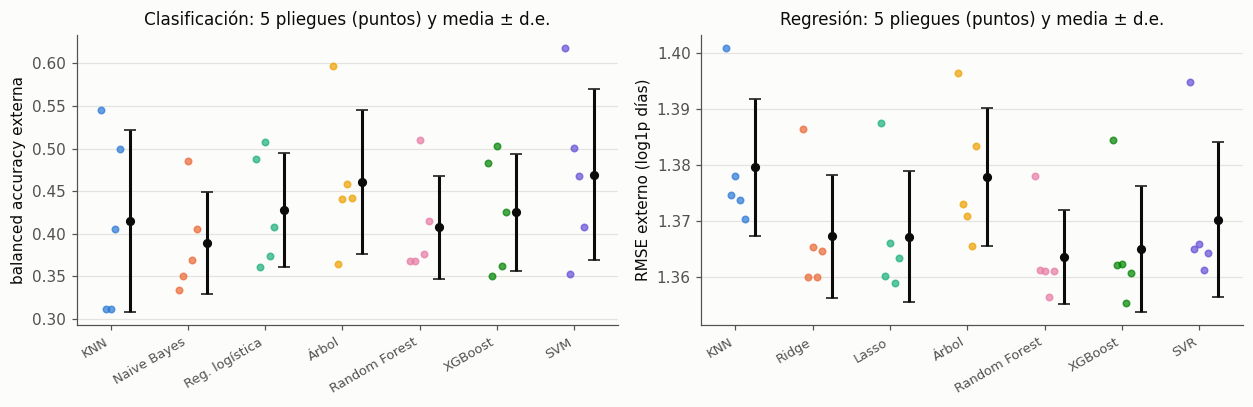

,Clasificación: combinación,balanced acc. (media ± d.e.),AUC (media ± d.e.)
KNN,SMOTE · Genética,0.415 ± 0.107,0.626 ± 0.060
Naive Bayes,ADASYN · Genética,0.389 ± 0.060,0.672 ± 0.064
Reg. logística,ADASYN · Bayesiana (TPE),0.427 ± 0.067,0.728 ± 0.041
Árbol,class_weight · Bayesiana (TPE),0.461 ± 0.084,0.660 ± 0.052
Random Forest,SMOTE · Bayesiana (TPE),0.407 ± 0.060,0.709 ± 0.060
XGBoost,class_weight · Bayesiana (TPE),0.425 ± 0.069,0.723 ± 0.044
SVM,SMOTE · Random,0.469 ± 0.101,0.712 ± 0.051


In [2]:
def best_rows(mt, metric, asc):
    b = mt.loc[mt.groupby('model')[f'outer_{metric}_mean'].idxmin() if asc else mt.groupby('model')[f'outer_{metric}_mean'].idxmax()]
    return b.set_index('model')
bc = best_rows(mc, 'recall', False).reindex(P.MODEL_ORDER_CLF)
br = best_rows(mr, 'rmse', True).reindex(P.MODEL_ORDER_REG)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for ax, b, metric, lab, f in [(axes[0], bc, 'recall', 'balanced accuracy externa', fc), (axes[1], br, 'rmse', 'RMSE externo (log1p días)', fr)]:
    for i, (m, r) in enumerate(b.iterrows()):
        vals = f[(f.model == m) & (f.balance == r.balance) & (f.optimizer == r.optimizer)][f'outer_{metric}']
        ax.scatter(np.full(len(vals), i) + np.linspace(-0.12, 0.12, len(vals)), vals, color=P.MODEL_COLORS[m], s=18, alpha=0.7)
        ax.errorbar(i + 0.25, r[f'outer_{metric}_mean'], yerr=r[f'outer_{metric}_std'], fmt='o', color=P.INK, ms=5, capsize=4)
    ax.set_xticks(range(len(b)), [M.PRETTY[m] for m in b.index], rotation=30, ha='right', fontsize=8.5)
    ax.set_ylabel(lab); ax.grid(axis='x', visible=False)
axes[0].set_title('Clasificación: 5 pliegues (puntos) y media ± d.e.'); axes[1].set_title('Regresión: 5 pliegues (puntos) y media ± d.e.')
fig.tight_layout(); P.save(fig, 'e3_robustez_pliegues'); plt.show()
pd.DataFrame({'Clasificación: combinación': [f'{M.PRETTY[r.balance]} · {M.PRETTY[r.optimizer]}' for _, r in bc.iterrows()],
              'balanced acc. (media ± d.e.)': [f'{r.outer_recall_mean:.3f} ± {r.outer_recall_std:.3f}' for _, r in bc.iterrows()],
              'AUC (media ± d.e.)': [f'{r.outer_auc_mean:.3f} ± {r.outer_auc_std:.3f}' for _, r in bc.iterrows()]},
             index=[M.PRETTY[m] for m in bc.index])

**Interpretación.** La variación entre pliegues externos es grande frente a las diferencias entre modelos. En balanced
accuracy las desviaciones van de ±0,06 (Naive Bayes, Random Forest) a ±0,10–0,11 (SVM y KNN con SMOTE),
mientras que las medias de los 7 modelos caben en un rango de 0,08 (0,389 a 0,469). Los puntos de cada
pliegue (izquierda) muestran que un mismo modelo puede pasar de 0,31 a 0,55 (KNN) o de 0,35 a 0,62 (SVM) según el pliegue: los
pliegues con 3 o 4 fallecimientos premian a los modelos que los marcan masivamente. En AUC la dispersión
es menor (±0,04 a ±0,06) y la logística, XGBoost y SVM quedan arriba (0,71 a 0,73). En regresión, en
cambio, la variación entre pliegues es pequeña (±0,008 a ±0,014 de RMSE) y ordena a los modelos con
claridad.

## 12.2 Sensibilidad a la semilla aleatoria

Para las combinaciones seleccionadas se repitió la validación anidada completa (búsqueda incluida)
con las semillas 7, 123 y 2024, además de la 42. Los datos y los pliegues no cambian: solo la
aleatoriedad del algoritmo. Se compara la desviación **entre semillas** (de la media de los 5
pliegues) con la desviación **entre pliegues**.

In [3]:
metric = {'clf': 'outer_recall', 'reg': 'outer_rmse'}
rows = []
for (t, m, b, o), d in st.groupby(['task', 'model', 'balance', 'optimizer']):
    k = metric[t]
    per_seed = d.groupby('seed')[k].mean()
    rows.append({'tarea': 'Clasificación' if t == 'clf' else 'Regresión',
                 'combinación': f'{M.PRETTY[m]} · {M.PRETTY[b]} · {M.PRETTY[o]}',
                 'semillas': len(per_seed), 'media': per_seed.mean(),
                 'd.e. entre semillas': per_seed.std(ddof=1), 'rango entre semillas': per_seed.max() - per_seed.min(),
                 'd.e. entre pliegues (semilla 42)': d[d.seed == C.SEED][k].std(ddof=1),
                 'hiperparámetros distintos elegidos (de 20 búsquedas)': d.params.nunique()})
seed_tab = pd.DataFrame(rows).set_index(['tarea', 'combinación'])
seed_tab['razón semillas / pliegues'] = seed_tab['d.e. entre semillas'] / seed_tab['d.e. entre pliegues (semilla 42)']
seed_tab.round(4)

semillas   media  \
tarea         combinación                                                  
Clasificación Random Forest · SMOTE · Bayesiana (TPE)          4  0.4033   
              SVM · SMOTE · Genética                           4  0.4118   
              SVM · SMOTE · Random                             4  0.4263   
              XGBoost · class_weight · Bayesiana (TPE)         4  0.4090   
Regresión     Random Forest · Sin balanceo · Genética          4  1.3644   
              Random Forest · Sin balanceo · Random            4  1.3645   
              XGBoost · Sin balanceo · Bayesiana (TPE)         4  1.3649   

                                                        d.e. entre semillas  \
tarea         combinación                                                     
Clasificación Random Forest · SMOTE · Bayesiana (TPE)                0.0042   
              SVM · SMOTE · Genética                                 0.0187   
              SVM · SMOTE · Random                                   0.0321   
              XGBoost · class_weight · Bayesiana (TPE)               0.0114   
Regresión     Random Forest · Sin balanceo · Genética                0.0007   
              Random Forest · Sin balanceo · Random                  0.0009   
              XGBoost · Sin balanceo · Bayesiana (TPE)               0.0007   

                                                        rango entre semillas  \
tarea         combinación                                                      
Clasificación Random Forest · SMOTE · Bayesiana (TPE)                 0.0079   
              SVM · SMOTE · Genética                                  0.0455   
              SVM · SMOTE · Random                                    0.0750   
              XGBoost · class_weight · Bayesiana (TPE)                0.0261   
Regresión     Random Forest · Sin balanceo · Genética                 0.0016   
              Random Forest · Sin balanceo · Random                   0.0022   
              XGBoost · Sin balanceo · Bayesiana (TPE)                0.0017   

                                                        d.e. entre pliegues (semilla 42)  \
tarea         combinación                                                                  
Clasificación Random Forest · SMOTE · Bayesiana (TPE)                             0.0605   
              SVM · SMOTE · Genética                                              0.0539   
              SVM · SMOTE · Random                                                0.1006   
              XGBoost · class_weight · Bayesiana (TPE)                            0.0689   
Regresión     Random Forest · Sin balanceo · Genética                             0.0104   
              Random Forest · Sin balanceo · Random                               0.0084   
              XGBoost · Sin balanceo · Bayesiana (TPE)                            0.0112   

                                                        hiperparámetros distintos elegidos (de 20 búsquedas)  \
tarea         combinación                                                                                      
Clasificación Random Forest · SMOTE · Bayesiana (TPE)                                                  20      
              SVM · SMOTE · Genética                                                                   20      
              SVM · SMOTE · Random                                                                     20      
              XGBoost · class_weight · Bayesiana (TPE)                                                 20      
Regresión     Random Forest · Sin balanceo · Genética                                                  20      
              Random Forest · Sin balanceo · Random                                                    20      
              XGBoost · Sin balanceo · Bayesiana (TPE)                                                 20      

                                                        razón semillas / pliegues  
tarea         co

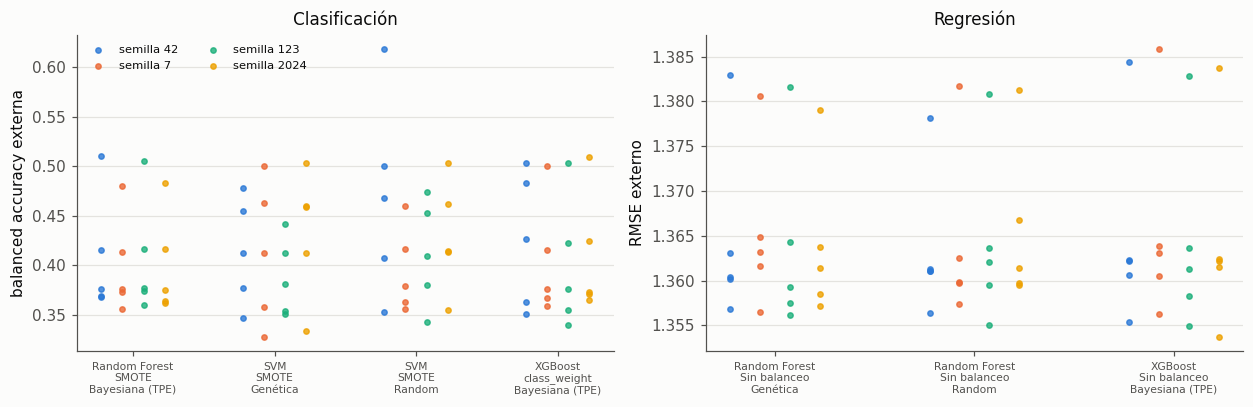

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for ax, t, lab in [(axes[0], 'clf', 'balanced accuracy externa'), (axes[1], 'reg', 'RMSE externo')]:
    d = st[st.task == t]
    combos = list(d.groupby(['model', 'balance', 'optimizer']).groups)
    for i, cmb in enumerate(combos):
        x = d[(d.model == cmb[0]) & (d.balance == cmb[1]) & (d.optimizer == cmb[2])]
        for j, s in enumerate([C.SEED] + SD.SEEDS):
            v = x[x.seed == s][metric[t]]
            ax.scatter(np.full(len(v), i + (j - 1.5) * 0.15), v, s=12, color=P.SERIES[j], label=f'semilla {s}' if i == 0 else None, alpha=0.8)
    ax.set_xticks(range(len(combos)), [f'{M.PRETTY[c[0]]}\n{M.PRETTY[c[1]]}\n{M.PRETTY[c[2]]}' for c in combos], fontsize=7)
    ax.set_ylabel(lab); ax.grid(axis='x', visible=False)
axes[0].legend(fontsize=7.5, ncol=2); axes[0].set_title('Clasificación'); axes[1].set_title('Regresión')
fig.tight_layout(); P.save(fig, 'e3_robustez_semillas'); plt.show()

**Interpretación.** Con los datos fijos, cambiar solo la semilla del algoritmo mueve poco a los modelos estables y mucho a
los inestables:

- **Random Forest con SMOTE** (clasificación) y todas las combinaciones de regresión: desviación entre
  semillas de 0,004 en balanced accuracy y de ≤ 0,001 en RMSE, entre 10 y 15 veces menor que la
  desviación entre pliegues.
- **SVM con SMOTE** es el más sensible: con la búsqueda aleatoria, la media de los 5 pliegues va de unas
  semillas a otras en un rango de 0,075 (desviación 0,032), y con la semilla 42 obtuvo 0,469, la más alta
  de las cuatro (la media de las cuatro semillas es 0,426). Es decir, parte de su primer puesto en la tabla
  maestra se debe a la semilla: SMOTE genera fallecimientos sintéticos distintos con cada semilla y la
  búsqueda aleatoria cae en configuraciones distintas.
- XGBoost con `class_weight` queda en medio (desviación 0,011).
- **Los hiperparámetros elegidos cambian siempre** (20 configuraciones distintas en 20 búsquedas por
  combinación): el paisaje es plano y muchas configuraciones son equivalentes, lo que ya se vio en el
  capítulo 7.

La conclusión práctica: el primer puesto de SVM con SMOTE no es robusto a la semilla, y la combinación
elegida «mejor» por balanced accuracy debe leerse con esa cautela.

## 12.3 ¿Las diferencias entre modelos superan la variabilidad de cada modelo?

Se compara la diferencia entre la mejor combinación y cada una de las demás (en el mismo pliegue,
pareada) con la desviación estándar entre pliegues de cada una. Si la diferencia media es menor que
esa desviación, la diferencia observada no se distingue del ruido de muestreo con estos datos; eso
motiva las pruebas formales del capítulo 13.

In [5]:
def diff_vs_noise(f, mt, metric, higher):
    top = mt.sort_values(f'outer_{metric}_mean', ascending=not higher).iloc[0]
    ref = f[(f.model == top.model) & (f.balance == top.balance) & (f.optimizer == top.optimizer)].set_index('fold')[f'outer_{metric}']
    best = mt.loc[mt.groupby('model')[f'outer_{metric}_mean'].idxmax() if higher else mt.groupby('model')[f'outer_{metric}_mean'].idxmin()]
    rows = []
    for _, r in best.iterrows():
        v = f[(f.model == r.model) & (f.balance == r.balance) & (f.optimizer == r.optimizer)].set_index('fold')[f'outer_{metric}']
        d = (ref - v) if higher else (v - ref)
        rows.append({'modelo': M.PRETTY[r.model], 'diferencia media con el mejor (pareada)': d.mean(),
                     'd.e. de la diferencia': d.std(ddof=1), 'd.e. entre pliegues del modelo': v.std(ddof=1),
                     '¿diferencia > d.e. del modelo?': bool(d.mean() > v.std(ddof=1)), 'pliegues donde el mejor gana': int((d > 0).sum())})
    return pd.DataFrame(rows).set_index('modelo').sort_values('diferencia media con el mejor (pareada)')
print('Clasificación (balanced accuracy):'); display(diff_vs_noise(fc, mc, 'recall', True).round(4))
print('Regresión (RMSE):'); display(diff_vs_noise(fr, mr, 'rmse', False).round(4))

Clasificación (balanced accuracy):


,diferencia media con el mejor (pareada),d.e. de la diferencia,d.e. entre pliegues del modelo,¿diferencia > d.e. del modelo?,pliegues donde el mejor gana
modelo,,,,,
SVM,0.0000,0.0000,0.1006,False,0
Árbol,0.0088,0.0356,0.0843,False,3
Reg. logística,0.0420,0.0659,0.0668,False,2
XGBoost,0.0443,0.0707,0.0689,False,3
KNN,0.0546,0.0998,0.1065,False,4
Random Forest,0.0621,0.1146,0.0605,True,2
Naive Bayes,0.0804,0.1208,0.0603,True,5


Regresión (RMSE):


,diferencia media con el mejor (pareada),d.e. de la diferencia,d.e. entre pliegues del modelo,¿diferencia > d.e. del modelo?,pliegues donde el mejor gana
modelo,,,,,
Random Forest,0.0000,0.0000,0.0084,False,0
XGBoost,0.0014,0.0029,0.0112,False,3
Lasso,0.0036,0.0039,0.0117,False,4
Ridge,0.0037,0.0035,0.0110,False,4
SVR,0.0066,0.0057,0.0139,False,5
Árbol,0.0143,0.0058,0.0123,True,5
KNN,0.0160,0.0051,0.0123,True,5


**Interpretación.** En clasificación, ninguna de las diferencias entre el mejor (SVM con SMOTE) y los demás supera la
desviación entre pliegues del propio modelo salvo en Random Forest y Naive Bayes, y aun en esos el mejor
gana solo en 2 y 5 de los 5 pliegues respectivamente. La logística, XGBoost y el árbol pierden en promedio
por 0,01 a 0,04, menos que su propia variación (0,07 a 0,08). En regresión ocurre al revés: Random Forest
gana a SVR, al árbol y a KNN en los 5 pliegues, y la diferencia con el árbol y con KNN (0,014 a 0,016)
supera la desviación de esos modelos; frente a XGBoost, Lasso y Ridge la diferencia (0,001 a 0,004) es
menor que el ruido. Con diferencias así de pequeñas y tantas comparaciones posibles, mirar las medias no
basta: el capítulo 13 aplica las pruebas formales.

## 12.4 Corrección del entregable 1: la brecha entre entrenamiento y validación

El profesor observó que la brecha del entregable 1 (balanced accuracy de 0,65 en entrenamiento
frente a 0,39 en validación) no se analizó a fondo. Como el balanced accuracy es el promedio del
recall de las 4 clases, la brecha se puede **descomponer por clase**:
brecha = ¼ Σₖ (recallₖ entrenamiento − recallₖ validación).

**(a) La logística del entregable 1.** La corrida con diseño temporal de Iván (sección 12.6)
reprodujo esa logística (C = 1, L2, `class_weight='balanced'`, 1.433 columnas) en los 3 pliegues
hacia adelante del entregable 1 y guardó el recall de Fallecimiento en entrenamiento y validación.

In [6]:
iv = pd.read_csv(C.RESULTS / 'disenio_temporal' / 'master_registry.csv')
e1 = iv[iv.model == 'logreg_e1'][['outer_fold', 'train_deaths', 'valid_deaths', 'train_balanced_accuracy', 'outer_balanced_accuracy',
                                  'train_recall_death', 'outer_recall_death']].copy()
e1['brecha total'] = e1.train_balanced_accuracy - e1.outer_balanced_accuracy
e1['aporte de Fallecimiento (¼ Δ recall)'] = (e1.train_recall_death - e1.outer_recall_death) / 4
e1['aporte de las otras 3 clases'] = e1['brecha total'] - e1['aporte de Fallecimiento (¼ Δ recall)']
e1.set_index('outer_fold').round(3)

,train_deaths,valid_deaths,train_balanced_accuracy,outer_balanced_accuracy,train_recall_death,outer_recall_death,brecha total,aporte de Fallecimiento (¼ Δ recall),aporte de las otras 3 clases
outer_fold,,,,,,,,,
1,16,1,0.670,0.380,1.0,0.0,0.290,0.25,0.040
2,27,3,0.668,0.383,1.0,0.0,0.285,0.25,0.035
3,37,8,0.650,0.392,1.0,0.0,0.258,0.25,0.008


**(b) Los mejores modelos de este entregable.** Para la mejor combinación de cada modelo se
reajusta en el entrenamiento de cada pliegue externo y se mide el recall por clase en ese mismo
entrenamiento y en el pliegue externo.

In [7]:
import json, warnings
from osha_e3 import search as S, data as D, models as MM, evaluation as E, cache
def run_gap():
    X, y, g, s = N.task_data('clf')
    rows = []
    for m, r in bc.iterrows():
        for f, (tr, te) in enumerate(N.outer_folds('clf')):
            pipe = S.refit('clf', m, json.loads(r.final_params), r.balance, X.iloc[tr], y[tr], C.SEED)
            for part, idx in [('entrenamiento', tr), ('validación', te)]:
                pred = pipe.predict_proba(X.iloc[idx]).argmax(1)
                rec = [((pred == k) & (y[idx] == k)).sum() / (y[idx] == k).sum() if (y[idx] == k).any() else np.nan for k in range(4)]
                rows.append({'model': m, 'fold': f, 'parte': part, **{f'recall_{k}': rec[k] for k in range(4)}})
    return pd.DataFrame(rows)
gap = cache.cached('robustez_gap', run_gap)
g = gap.groupby(['model', 'parte'])[[f'recall_{k}' for k in range(4)]].mean().unstack('parte')
out = pd.DataFrame(index=[M.PRETTY[m] for m in P.MODEL_ORDER_CLF])
for k, name in enumerate(C.CLASS_NAMES):
    out[f'recall entren. {name}'] = g[(f'recall_{k}', 'entrenamiento')].reindex(P.MODEL_ORDER_CLF).to_numpy()
    out[f'recall valid. {name}'] = g[(f'recall_{k}', 'validación')].reindex(P.MODEL_ORDER_CLF).to_numpy()
deltas = pd.DataFrame({f'Δ {n}': out[f'recall entren. {n}'] - out[f'recall valid. {n}'] for n in C.CLASS_NAMES})
out['brecha balanced acc.'] = deltas.mean(axis=1)
out['aporte de Fallecimiento'] = deltas[f'Δ {C.CLASS_NAMES[0]}'] / 4
out['aporte de las 3 clases frecuentes'] = out['brecha balanced acc.'] - out['aporte de Fallecimiento']
out.round(3)

,recall entren. Fallecimiento,recall valid. Fallecimiento,recall entren. Días de ausencia,recall valid. Días de ausencia,recall entren. Traslado/restricción,recall valid. Traslado/restricción,recall entren. Otro registrable,recall valid. Otro registrable,brecha balanced acc.,aporte de Fallecimiento,aporte de las 3 clases frecuentes
KNN,1.000,0.812,0.199,0.139,0.555,0.460,0.492,0.462,0.093,0.047,0.046
Naive Bayes,0.848,0.000,0.344,0.338,0.625,0.584,0.565,0.534,0.232,0.212,0.020
Reg. logística,1.000,0.000,0.407,0.377,0.620,0.535,0.637,0.610,0.286,0.250,0.036
Árbol,1.000,0.500,0.267,0.252,0.700,0.641,0.467,0.464,0.144,0.125,0.019
Random Forest,0.971,0.000,0.407,0.346,0.670,0.572,0.652,0.594,0.297,0.243,0.054
XGBoost,1.000,0.125,0.378,0.331,0.734,0.638,0.586,0.547,0.264,0.219,0.045
SVM,1.000,0.500,0.289,0.259,0.599,0.548,0.621,0.590,0.153,0.125,0.028


**Interpretación.** **La brecha del entregable 1 se debe casi entera a Fallecimiento.** En la logística del entregable 1 la
brecha de balanced accuracy entre entrenamiento y validación es de 0,26 a 0,29 en los 3 pliegues, y en
todos el recall de Fallecimiento es 1,0 en entrenamiento y 0 en validación: esa clase aporta 0,25 a la
brecha y las otras tres solo 0,01 a 0,04. Con 1.433 columnas one-hot y `class_weight='balanced'`, el modelo
tiene parámetros suficientes para separar los 16 a 37 fallecimientos del entrenamiento (cada uno pesa
como unos 3.900 casos de las demás clases), pero esa separación es memoria, no un patrón: no reconoce
ninguno de los fallecimientos de validación. En las tres clases frecuentes el modelo casi no sobreajusta.

**En los modelos de este entregable pasa lo mismo, con menos intensidad en algunos.** La brecha va de 0,09
(KNN) a 0,30 (Random Forest), y Fallecimiento aporta entre el 51 % (KNN) y el 91 % (Naive Bayes) de ella: la
logística, Random Forest, XGBoost y Naive Bayes reconocen casi todos los fallecimientos de entrenamiento
(recall 0,85 a 1,0) y muy pocos en validación (0 a 0,13). En las tres clases frecuentes la brecha es de
0,02 a 0,05, típica de un modelo con poca varianza. Agrupar NAICS y SOC (210 columnas en lugar de 1.433)
no basta para evitar que se memoricen 5 a 9 casos. **Conclusión:** el problema no es sobreajuste general,
sino que con menos de 10 ejemplos de una clase no hay patrón que aprender; las métricas de 4 clases
sobrestiman la brecha y el desempeño de entrenamiento, y por eso el informe reporta también las métricas
de las 3 clases frecuentes.

## 12.5 Corrección del entregable 1: ¿qué pasa si se quita `time_unknown`?

`time_unknown` supera el umbral de colinealidad (sección 4.6). Se reajusta la mejor combinación de
cada modelo **sin esa variable** en los 5 pliegues externos (mismos hiperparámetros) y se compara,
pliegue a pliegue, con el resultado original.

In [8]:
def run_ablation():
    X, y, g, s = N.task_data('clf')
    Xd = X.drop(columns=['time_unknown'])
    rows = []
    for m, r in bc.iterrows():
        for f, (tr, te) in enumerate(N.outer_folds('clf')):
            for label, XX in [('con time_unknown', X), ('sin time_unknown', Xd)]:
                pipe = MM.make_pipeline('clf', m, json.loads(r.final_params), r.balance, C.SEED)
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')
                    pipe.fit(XX.iloc[tr], y[tr])
                met = E.classification_metrics(y[te], pipe.predict_proba(XX.iloc[te]))
                rows.append({'model': m, 'fold': f, 'variante': label, **met})
    return pd.DataFrame(rows)
abl = cache.cached('robustez_ablation_time_unknown', run_ablation)
rows = []
for m in P.MODEL_ORDER_CLF:
    a = abl[(abl.model == m) & (abl.variante == 'con time_unknown')].set_index('fold')
    b = abl[(abl.model == m) & (abl.variante == 'sin time_unknown')].set_index('fold')
    rows.append({'modelo': M.PRETTY[m], **{f'Δ {k} (sin − con)': (b[k] - a[k]).mean() for k in ['recall', 'f1', 'auc', 'log_loss']},
                 'd.e. entre pliegues (balanced acc.)': a.recall.std(ddof=1)})
pd.DataFrame(rows).set_index('modelo').round(4)

,Δ recall (sin − con),Δ f1 (sin − con),Δ auc (sin − con),Δ log_loss (sin − con),d.e. entre pliegues (balanced acc.)
modelo,,,,,
KNN,0.0136,0.0012,0.0163,0.0057,0.0685
Naive Bayes,0.0024,0.0029,0.0207,-0.0307,0.0601
Reg. logística,0.0015,0.0010,-0.0034,0.0003,0.0593
Árbol,0.0000,0.0000,0.0055,0.0000,0.0795
Random Forest,0.0001,-0.0001,0.0017,-0.0008,0.0617
XGBoost,0.0011,0.0026,0.0010,0.0004,0.0604
SVM,0.0003,0.0001,0.0007,0.0011,0.0813


**Interpretación.** Quitar `time_unknown` no cambia nada relevante: las diferencias en balanced accuracy, F1 y AUC van de 0 a
0,02, todas mucho menores que la desviación entre pliegues (0,06 a 0,08); en el árbol la diferencia es
exactamente 0 (nunca usó esa variable) y en Random Forest y SVM es de una milésima. Los cambios mayores
son en KNN y Naive Bayes, que mejoran ligeramente sin ella (AUC +0,016 y +0,021): son los dos modelos que
tratan todas las columnas por igual (distancias o independencia), así que contar dos veces la misma
información (hora desconocida) les perjudica. Coherente con el umbral de colinealidad del entregable 1,
**la variable sobra**: no aporta información y en dos modelos estorba un poco. No se reentrenaron las 140
combinaciones sin ella (no cambiaría las conclusiones y costaría otra corrida completa); queda anotado
como decisión para cualquier modelo que se use después.

## 12.6 Diseño alternativo: validación anidada con pliegues temporales (corrida de Iván Berrio)

En paralelo, Iván corrió una validación anidada con otro diseño (tablas en
`results/disenio_temporal/`): 3 pliegues externos **hacia adelante en el tiempo** (los del
entregable 1), NAICS y SOC completos con el agrupamiento de categorías raras como hiperparámetro,
búsqueda en el 25 % del entrenamiento externo (con todas las muertes) y reentrenamiento con el
100 %, 20 evaluaciones por optimizador y SMOTE/ADASYN solo sobre Fallecimiento. KNN ×
`class_weight` no se corrió (108 combinaciones). Comparar los dos diseños indica qué conclusiones
dependen de cómo se valida.

Combinaciones comunes: 108
Spearman entre diseños (balanced accuracy): rho = 0.48 (p = 1.7e-07)
Spearman entre diseños (AUC macro): rho = 0.77 (p = 2.1e-22)
Spearman entre diseños (F1 macro): rho = 0.65 (p = 3.4e-14)


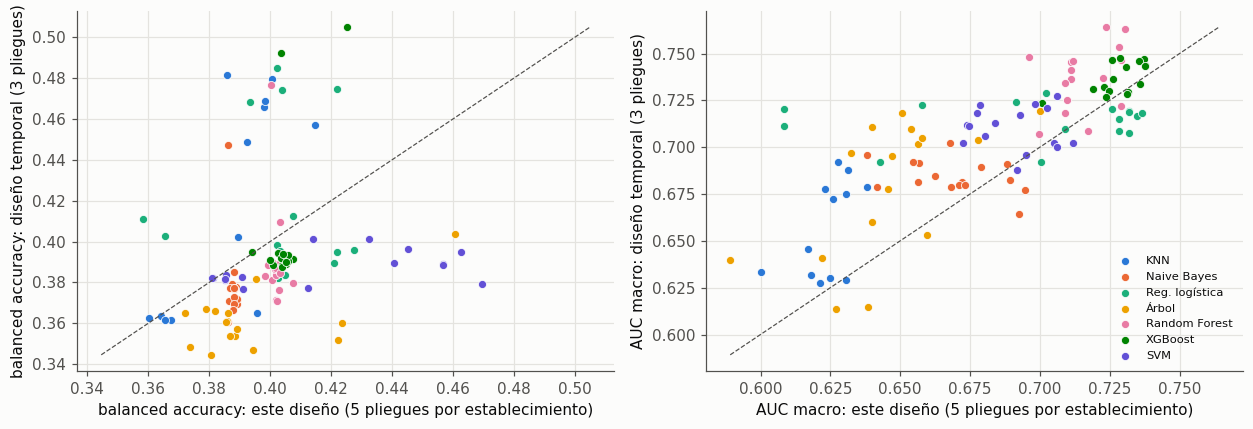

,model,balance,optimizer,deaths,hits,pred_death,prec_death,BA_pooled
98,xgboost,class_weight,bayes,12,8,5337,0.0015,0.5160
99,xgboost,class_weight,genetic,12,6,3950,0.0015,0.4826
53,random_forest,class_weight,random,12,6,6256,0.0010,0.4720
17,logreg,class_weight,bayes,12,4,2205,0.0018,0.4543
9,knn,smote,bayes,12,5,3138,0.0016,0.4479
50,random_forest,class_weight,bayes,12,4,2527,0.0016,0.4460


In [9]:
from scipy.stats import spearmanr
pooled = pd.read_csv(C.RESULTS / 'disenio_temporal' / 'pooled_summary.csv')
ivm = iv[~iv.model.isin(['dummy', 'logreg_e1'])].groupby(['model', 'balance', 'optimizer']).agg(
    ba_temporal=('outer_balanced_accuracy', 'mean'), auc_temporal=('outer_roc_auc_macro_ovr', 'mean'),
    f1_temporal=('outer_f1_macro', 'mean')).reset_index()
both = mc.merge(ivm, on=['model', 'balance', 'optimizer'])
print('Combinaciones comunes:', len(both))
for a, b, lab in [('outer_recall_mean', 'ba_temporal', 'balanced accuracy'), ('outer_auc_mean', 'auc_temporal', 'AUC macro'),
                  ('outer_f1_mean', 'f1_temporal', 'F1 macro')]:
    rho, p = spearmanr(both[a], both[b])
    print(f'Spearman entre diseños ({lab}): rho = {rho:.2f} (p = {p:.2g})')
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for ax, a, b, lab in [(axes[0], 'outer_recall_mean', 'ba_temporal', 'balanced accuracy'), (axes[1], 'outer_auc_mean', 'auc_temporal', 'AUC macro')]:
    for m in P.MODEL_ORDER_CLF:
        x = both[both.model == m]
        ax.scatter(x[a], x[b], color=P.MODEL_COLORS[m], s=28, label=M.PRETTY[m], edgecolor='white', linewidth=0.5)
    lo = min(both[a].min(), both[b].min()); hi = max(both[a].max(), both[b].max())
    ax.plot([lo, hi], [lo, hi], color=P.INK2, ls='--', lw=0.8)
    ax.set_xlabel(f'{lab}: este diseño (5 pliegues por establecimiento)'); ax.set_ylabel(f'{lab}: diseño temporal (3 pliegues)')
axes[1].legend(fontsize=7.5, loc='lower right')
fig.tight_layout(); P.save(fig, 'e3_robustez_disenios'); plt.show()
top_iv = pooled[~pooled.model.isin(['dummy'])].sort_values('BA_pooled', ascending=False).head(6)
top_iv[['model', 'balance', 'optimizer', 'deaths', 'hits', 'pred_death', 'prec_death', 'BA_pooled']].round(4)

**Interpretación.** **Los dos diseños coinciden en lo que importa y discrepan en el balanced accuracy.** Sobre las 108
combinaciones comunes, el ordenamiento por AUC macro es bastante parecido entre diseños (Spearman 0,77), el
de F1 macro razonablemente (0,65) y el de balanced accuracy solo moderadamente (0,48). Es lo esperado: AUC y
F1 dependen poco de Fallecimiento y el balanced accuracy depende mucho, y cada diseño tiene muy pocos
fallecimientos en sus pliegues (12 en total en el temporal; 9 en esta submuestra).

La corrida temporal llega a la misma advertencia por otro camino: su mejor balanced accuracy (0,516,
XGBoost con `class_weight` y búsqueda bayesiana) acierta 8 de 12 fallecimientos marcando 5.337 casos como
fallecimiento (precisión del 0,15 %). Las seis combinaciones con mejor balanced accuracy en ese diseño
tienen la misma firma: miles de casos marcados para acertar 4 a 8 fallecimientos. **Conclusiones robustas
a los dos diseños:** (1) el desempeño en las clases frecuentes es moderado (AUC ~0,70); (2) ningún modelo
detecta Fallecimiento de forma útil; (3) las combinaciones «ganadoras» por balanced accuracy lo son por
marcar Fallecimiento masivamente, no por clasificar mejor.